In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [57]:
df = pd.read_excel("Cleaned_DataV4.xlsx")

In [ ]:
df.head()

In [59]:
df_clean = df.copy()

In [60]:
print("Shape:", df_clean.shape)
print("Duplicate:", df_clean.duplicated().sum())
print("\nMissing:")
print(df_clean.isna().sum().sort_values(ascending=False))

Shape: (36722, 16)
Duplicate: 3

Missing:
Ghi chú              21923
Giới tính                0
Ngày nhập học            0
Ngày sinh                0
HKTT_Huyện               0
Khu vực                  0
Tên tỉnh THPT            0
HKTT_Tỉnh                0
Trường tốt nghiệp        0
Khóa học                 0
Loại đào tạo             0
Bậc đào tạo              0
Ngành                    0
Nghề                     0
Niên khóa                0
Trạng thái               0
dtype: int64


In [61]:
# Lọc sinh viên Trung cấp
trung_cap = df_clean[
    df_clean["Bậc đào tạo"] == "Trung cấp"
]

print("Tổng sinh viên Trung cấp:", len(trung_cap))

Tổng sinh viên Trung cấp: 14358


In [62]:
for col in ["Tên tỉnh THPT", "Trường tốt nghiệp"]:
    missing = (
        trung_cap[col].isna()
        | trung_cap[col].eq("Không xác định")
    ).sum()

    total = len(trung_cap)

    print(f"\n{col}")
    print("Không xác định:", missing)
    print(f"Tỷ lệ: {missing / total * 100:.2f}%")


Tên tỉnh THPT
Không xác định: 74
Tỷ lệ: 0.52%

Trường tốt nghiệp
Không xác định: 0
Tỷ lệ: 0.00%


In [63]:
trung_cap["Trường tốt nghiệp"].value_counts(dropna=False).head(30)

Trường tốt nghiệp
KHÔNG Xác Định             9584
THCS Phan Bội Châu          146
THCS Ngô Quyền              116
THCS Lê Lợi                 115
THCS Tân Bình               105
THCS Hoàng Hoa Thám          95
THCS Võ Văn Tần              88
THCS Lý Thường Kiệt          82
THCS Nguyễn Huệ              77
THCS Quang Trung             76
THCS Ngô Sĩ Liên             70
THCS Nguyễn Trãi             68
THCS Nguyễn Vĩnh Nghiệp      66
THCS Phạm Ngọc Thạch         62
THCS Thoại Ngọc Hầu          62
THCS Nguyễn Văn Trỗi         60
THCS Đoàn Thị Điểm           60
THCS Lê Quý Đôn              59
THCS Tân Phú Trung           59
THCS Âu Lạc                  58
THCS Trường Chinh            56
THCS Võ Thành Trang          56
THCS Tân Thới Hòa            56
THCS Lê Anh Xuân             55
THCS Huỳnh Văn Nghệ          51
THCS Ngô Tất Tố              50
THCS Trần Phú                47
THCS Đào Duy Anh             47
THCS Trần Quốc Toản          46
THCS Hoàng Diệu              38
Name: count, dtype: in

In [64]:
for bac in ["Trung cấp", "Cao đẳng"]:
    temp = df_clean[df_clean["Bậc đào tạo"] == bac]

    missing = (
        temp["Trường tốt nghiệp"].isna()
        | temp["Trường tốt nghiệp"]
              .str.upper()
              .eq("Không xác định")
    )

    print(f"{bac}:")
    print(f"  Tổng: {len(temp)}")
    print(f"  Thiếu trường: {missing.sum()}")
    print(f"  Tỷ lệ thiếu: {missing.mean()*100:.2f}%")

Trung cấp:
  Tổng: 14358
  Thiếu trường: 0
  Tỷ lệ thiếu: 0.00%
Cao đẳng:
  Tổng: 22364
  Thiếu trường: 0
  Tỷ lệ thiếu: 0.00%


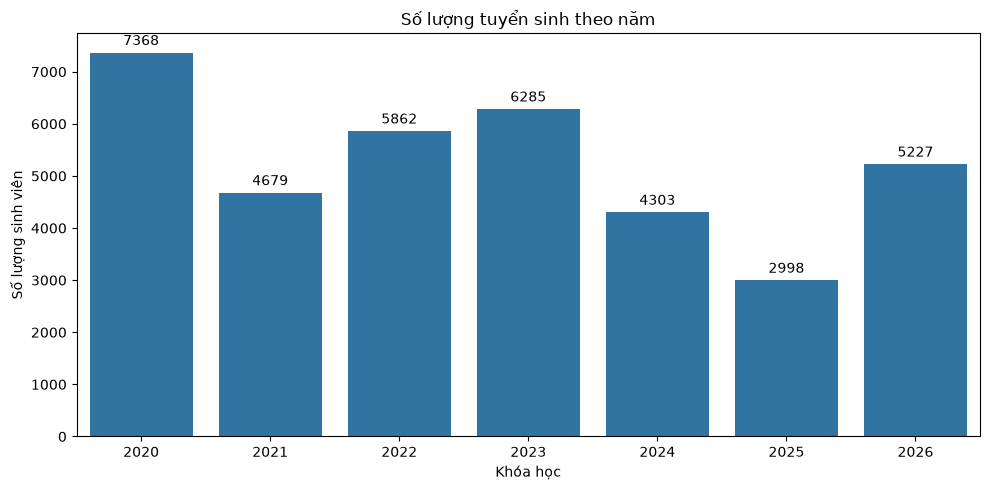

In [65]:
year_count = (
    df_clean
    .groupby("Khóa học")
    .size()
    .reset_index(name="Số lượng")
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=year_count,
    x="Khóa học",
    y="Số lượng"
)

ax.bar_label(ax.containers[0], fmt="%d", padding=3)

plt.title("Số lượng tuyển sinh theo năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.tight_layout()
plt.show()

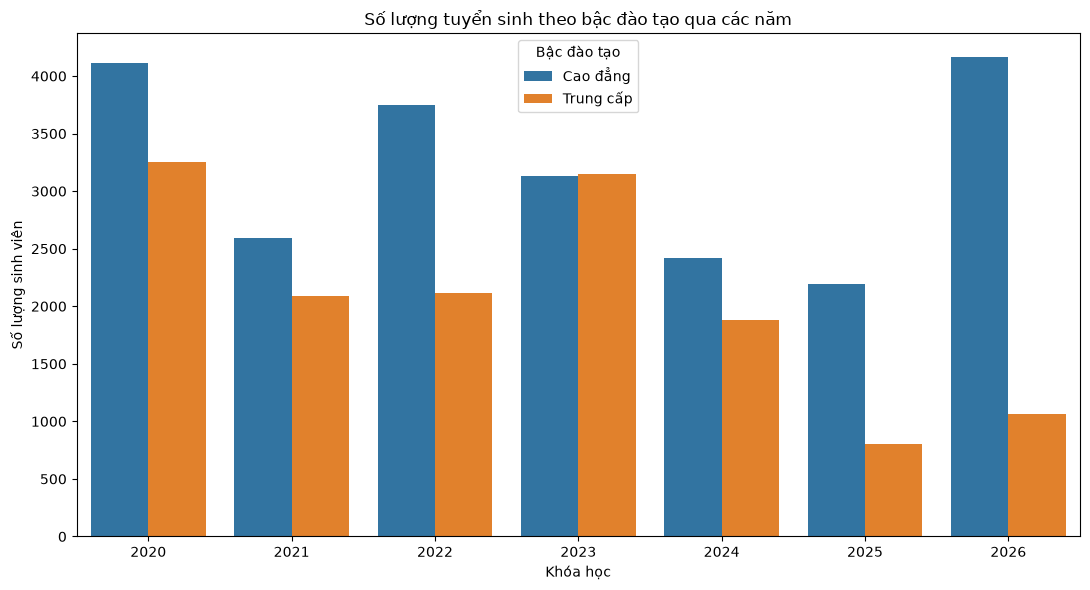

In [66]:
level_year = (
    df_clean
    .groupby(["Khóa học", "Bậc đào tạo"])
    .size()
    .reset_index(name="Số lượng")
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=level_year,
    x="Khóa học",
    y="Số lượng",
    hue="Bậc đào tạo"
)

plt.title("Số lượng tuyển sinh theo bậc đào tạo qua các năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")
plt.legend(title="Bậc đào tạo")

plt.tight_layout()
plt.show()

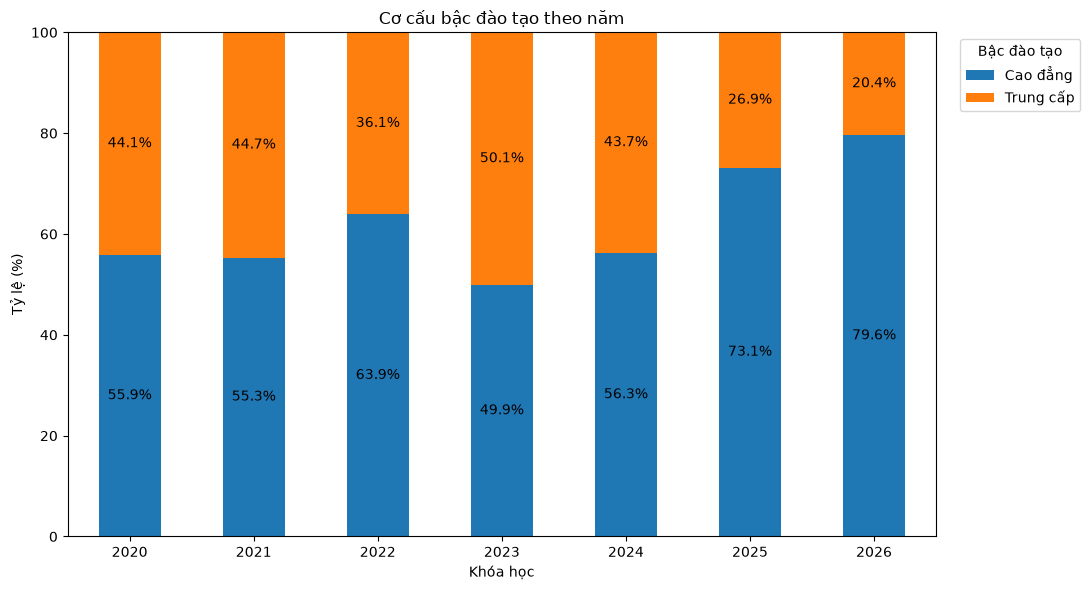

In [67]:
level_year["Tổng năm"] = ( 
    level_year .groupby("Khóa học")["Số lượng"] 
        .transform("sum") ) 
level_year["Tỷ lệ (%)"] = ( level_year["Số lượng"] / level_year["Tổng năm"] * 100 )

level_pivot = level_year.pivot(
    index="Khóa học",
    columns="Bậc đào tạo",
    values="Tỷ lệ (%)"
)

ax = level_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

# Hiển thị % trong từng phần
for container in ax.containers:
    labels = [
        f"{v:.1f}%" if v >= 5 else ""
        for v in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center"
    )

plt.title("Cơ cấu bậc đào tạo theo năm")
plt.xlabel("Khóa học")
plt.ylabel("Tỷ lệ (%)")

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Bậc đào tạo",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

In [68]:
print(df_clean["Loại đào tạo"].value_counts())

Loại đào tạo
Chính quy 2.5 năm                   15169
Chính quy 3 năm                     14000
Liên thông                           5025
Liên thông B                          971
Chất lượng cao                        646
Chính quy 1N3                         250
Chất lượng cao TTTN Nhật              242
Liên kết Quốc tế                      159
Chính quy 1 năm(Buổi tối)             108
Chất lượng cao song hành Vinfast       85
Song hành Doanh nghiệp                 67
Name: count, dtype: int64


In [69]:
type_year = (
    df_clean
    .groupby(["Khóa học", "Loại đào tạo"])
    .size()
    .reset_index(name="Số lượng")
)

In [70]:
top5_types = (
    df_clean
    .groupby("Loại đào tạo")
    .size()
    .nlargest(5)
    .index
)

type_year_top5 = type_year[
    type_year["Loại đào tạo"].isin(top5_types)
]

In [71]:
level_type = (
    df_clean
    .groupby(["Bậc đào tạo", "Loại đào tạo"])
    .size()
    .reset_index(name="Số lượng")
    .sort_values(
        ["Bậc đào tạo", "Số lượng"],
        ascending=[True, False]
    )
)

display(level_type)

,Bậc đào tạo,Loại đào tạo,Số lượng
0,Cao đẳng,Chính quy 2.5 năm,15169
5,Cao đẳng,Liên thông,5025
6,Cao đẳng,Liên thông B,971
1,Cao đẳng,Chất lượng cao,646
2,Cao đẳng,Chất lượng cao TTTN Nhật,242
4,Cao đẳng,Liên kết Quốc tế,159
3,Cao đẳng,Chất lượng cao song hành Vinfast,85
7,Cao đẳng,Song hành Doanh nghiệp,67
10,Trung cấp,Chính quy 3 năm,14000
9,Trung cấp,Chính quy 1N3,250


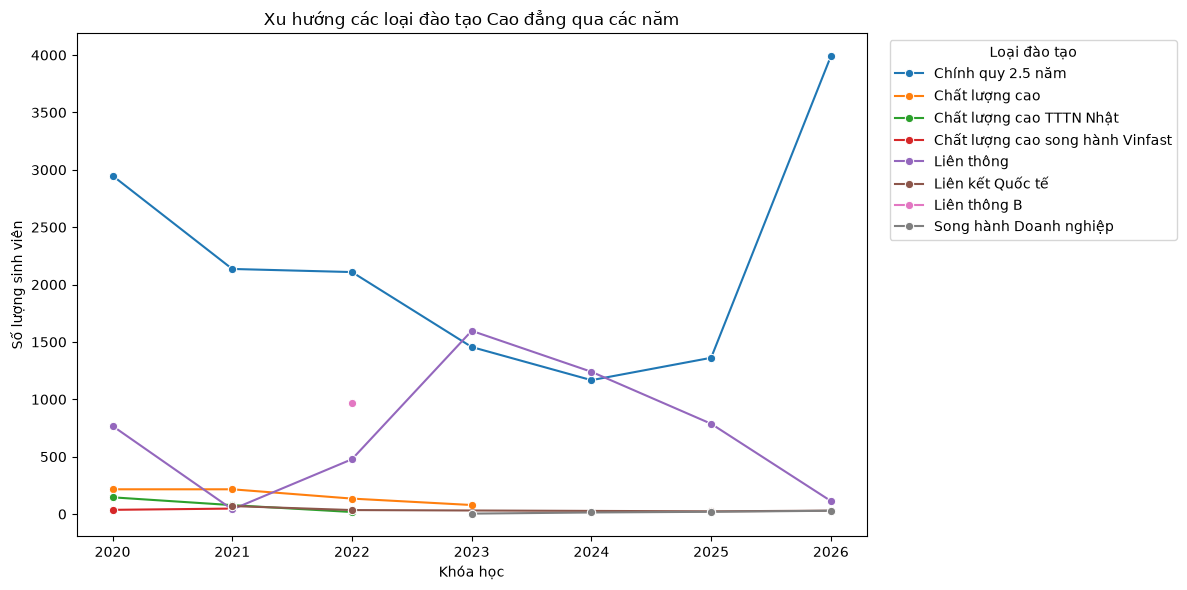

In [72]:

cd_type_year = (
    df_clean[df_clean["Bậc đào tạo"] == "Cao đẳng"]
    .groupby(["Khóa học", "Loại đào tạo"])
    .size()
    .reset_index(name="Số lượng")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=cd_type_year,
    x="Khóa học",
    y="Số lượng",
    hue="Loại đào tạo",
    marker="o"
)

plt.title("Xu hướng các loại đào tạo Cao đẳng qua các năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")
plt.legend(title="Loại đào tạo", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

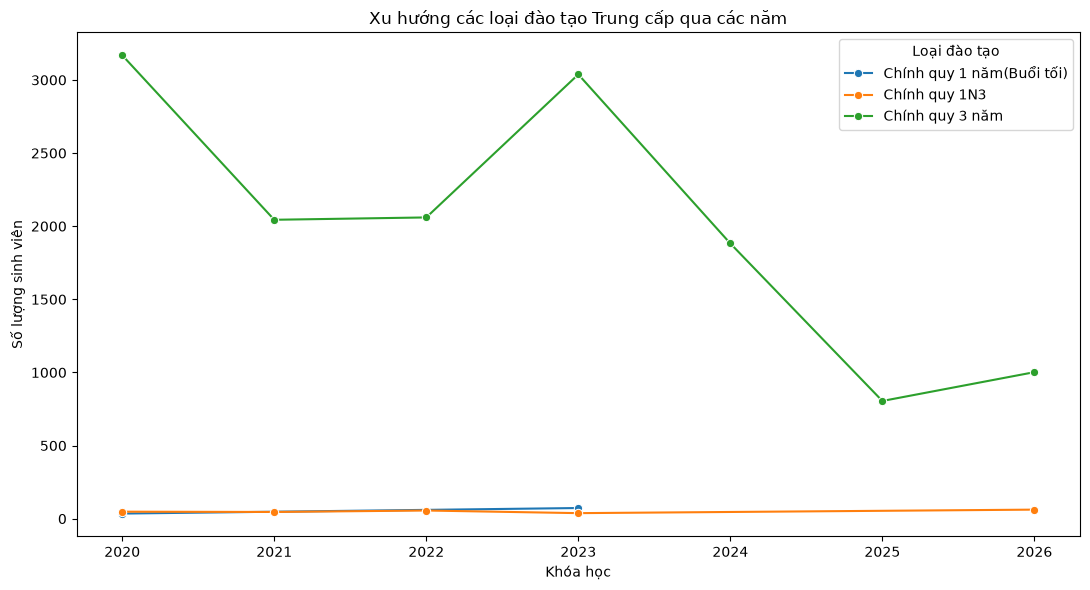

In [73]:
tc_type_year = (
    df_clean[df_clean["Bậc đào tạo"] == "Trung cấp"]
    .groupby(["Khóa học", "Loại đào tạo"])
    .size()
    .reset_index(name="Số lượng")
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=tc_type_year,
    x="Khóa học",
    y="Số lượng",
    hue="Loại đào tạo",
    marker="o"
)

plt.title("Xu hướng các loại đào tạo Trung cấp qua các năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")
plt.legend(title="Loại đào tạo")

plt.tight_layout()
plt.show()

In [74]:
#Ngành/Nghề × Khóa học

In [75]:
major_year = (
    df_clean
    .groupby(["Khóa học", "Ngành"])
    .size()
    .reset_index(name="Số lượng")
    .sort_values(ascending=False, by="Số lượng")
)

display(major_year.head(50))

,Khóa học,Ngành,Số lượng
13,2020,Công nghệ ô tô,1632
88,2022,Công nghệ ô tô,1272
125,2023,Công nghệ ô tô,1178
51,2021,Công nghệ ô tô,1080
243,2026,Công nghệ ô tô,935
164,2024,Công nghệ ô tô,730
203,2025,Công nghệ ô tô,623
4,2020,Công nghệ kỹ thuật cơ khí,501
234,2026,Công nghệ kỹ thuật cơ khí,464
80,2022,Công nghệ kỹ thuật cơ khí,445


In [124]:
top5_major = (
    df_clean
    .groupby("Ngành")
    .size()
    .nlargest(5)
    .index
)

major_year_top10 = major_year[
    major_year["Ngành"].isin(top5_major)
]

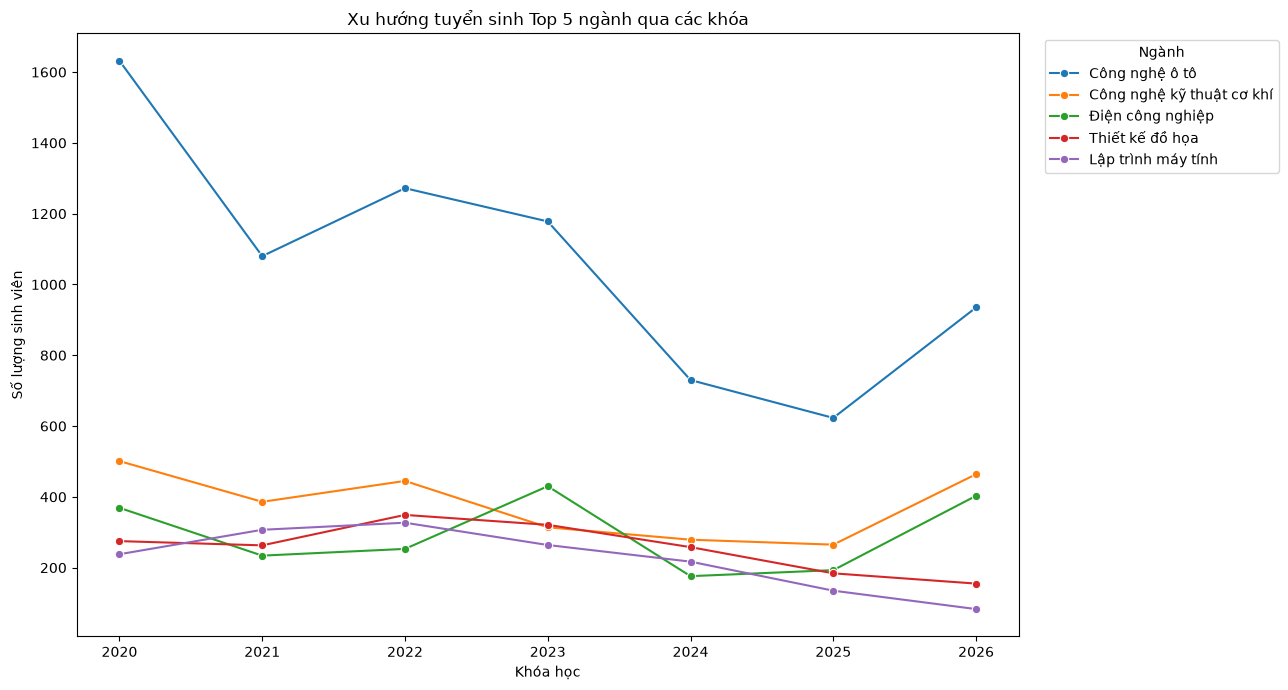

In [125]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=major_year_top10,
    x="Khóa học",
    y="Số lượng",
    hue="Ngành",
    marker="o"
)

plt.title("Xu hướng tuyển sinh Top 5 ngành qua các khóa")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.legend(
    title="Ngành",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [81]:
major_pivot = (
    major_year
    .pivot(
        index="Khóa học",
        columns="Ngành",
        values="Số lượng"
    )
    .fillna(0)
)

display(major_pivot)

Ngành,An ninh mạng,Bảo trì hệ thống thiết bị công nghiệp,Chế tạo khuôn mẫu,Công nghệ chế tạo máy,Công nghệ kỹ thuật cơ khí,Công nghệ kỹ thuật máy tính,Công nghệ kỹ thuật nhiệt,Công nghệ kỹ thuật phần cứng máy tính,Công nghệ kỹ thuật điều khiển tự động,Công nghệ kỹ thuật điều khiển và tự động hóa,...,Tiếng Anh,Tiếng Hàn Quốc,Tiếng Nhật,Truyền thông và mạng máy tính,Tài chính doanh nghiệp,"Vận hành, sửa chữa thiết bị lạnh",Điện công nghiệp,Điện công nghiệp.,Điện tử công nghiệp,Đồ họa đa phương tiện
Khóa học,,,,,,,,,,,,,,,,,,,,,
2020,37.0,25.0,20.0,170.0,501.0,75.0,181.0,77.0,38.0,91.0,...,274.0,0.0,0.0,0.0,89.0,165.0,369.0,0.0,0.0,98.0
2021,38.0,0.0,0.0,76.0,386.0,65.0,56.0,53.0,28.0,51.0,...,168.0,19.0,8.0,0.0,53.0,122.0,234.0,0.0,0.0,63.0
2022,51.0,0.0,0.0,119.0,445.0,118.0,20.0,71.0,27.0,45.0,...,347.0,26.0,47.0,0.0,47.0,174.0,253.0,0.0,0.0,108.0
2023,24.0,0.0,0.0,126.0,314.0,78.0,36.0,46.0,0.0,63.0,...,260.0,206.0,103.0,0.0,53.0,150.0,430.0,0.0,0.0,133.0
2024,41.0,0.0,0.0,58.0,279.0,64.0,17.0,35.0,17.0,15.0,...,249.0,188.0,25.0,0.0,25.0,119.0,176.0,0.0,10.0,116.0
2025,10.0,0.0,0.0,46.0,265.0,73.0,23.0,17.0,1.0,67.0,...,135.0,35.0,42.0,0.0,11.0,86.0,193.0,4.0,13.0,49.0
2026,31.0,28.0,7.0,121.0,464.0,79.0,74.0,33.0,17.0,323.0,...,100.0,96.0,33.0,7.0,13.0,144.0,403.0,9.0,130.0,55.0


In [82]:
major_growth = (
    major_pivot
    .pct_change(fill_method=None) * 100
).round(2)

# Năm trước = 0 → không tính được % tăng trưởng
previous = major_pivot.shift(1)

major_growth = major_growth.mask(previous == 0)

display(major_growth)

Ngành,An ninh mạng,Bảo trì hệ thống thiết bị công nghiệp,Chế tạo khuôn mẫu,Công nghệ chế tạo máy,Công nghệ kỹ thuật cơ khí,Công nghệ kỹ thuật máy tính,Công nghệ kỹ thuật nhiệt,Công nghệ kỹ thuật phần cứng máy tính,Công nghệ kỹ thuật điều khiển tự động,Công nghệ kỹ thuật điều khiển và tự động hóa,...,Tiếng Anh,Tiếng Hàn Quốc,Tiếng Nhật,Truyền thông và mạng máy tính,Tài chính doanh nghiệp,"Vận hành, sửa chữa thiết bị lạnh",Điện công nghiệp,Điện công nghiệp.,Điện tử công nghiệp,Đồ họa đa phương tiện
Khóa học,,,,,,,,,,,,,,,,,,,,,
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021,2.70,-100.0,-100.0,-55.29,-22.95,-13.33,-69.06,-31.17,-26.32,-43.96,...,-38.69,NaN,NaN,NaN,-40.45,-26.06,-36.59,NaN,NaN,-35.71
2022,34.21,NaN,NaN,56.58,15.28,81.54,-64.29,33.96,-3.57,-11.76,...,106.55,36.84,487.50,NaN,-11.32,42.62,8.12,NaN,NaN,71.43
2023,-52.94,NaN,NaN,5.88,-29.44,-33.90,80.00,-35.21,-100.00,40.00,...,-25.07,692.31,119.15,NaN,12.77,-13.79,69.96,NaN,NaN,23.15
2024,70.83,NaN,NaN,-53.97,-11.15,-17.95,-52.78,-23.91,NaN,-76.19,...,-4.23,-8.74,-75.73,NaN,-52.83,-20.67,-59.07,NaN,NaN,-12.78
2025,-75.61,NaN,NaN,-20.69,-5.02,14.06,35.29,-51.43,-94.12,346.67,...,-45.78,-81.38,68.00,NaN,-56.00,-27.73,9.66,NaN,30.0,-57.76
2026,210.00,NaN,NaN,163.04,75.09,8.22,221.74,94.12,1600.00,382.09,...,-25.93,174.29,-21.43,NaN,18.18,67.44,108.81,125.0,900.0,12.24


In [83]:
display(
    major_growth[list(top5_major)]
)

Ngành,Công nghệ ô tô,Công nghệ kỹ thuật cơ khí,Điện công nghiệp,Thiết kế đồ họa,Lập trình máy tính
Khóa học,,,,,
2020,NaN,NaN,NaN,NaN,NaN
2021,-33.82,-22.95,-36.59,-4.36,28.99
2022,17.78,15.28,8.12,32.70,6.51
2023,-7.39,-29.44,69.96,-8.02,-19.27
2024,-38.03,-11.15,-59.07,-19.63,-17.80
2025,-14.66,-5.02,9.66,-28.68,-37.79
2026,50.08,75.09,108.81,-15.76,-38.52


In [84]:
growth_2026 = (
    major_growth
    .loc[2026]
    .replace([float("inf"), -float("inf")], pd.NA)
    .dropna()
    .sort_values(ascending=False)
)

display(growth_2026.head(10))

Ngành
Công nghệ kỹ thuật điều khiển tự động           1600.00
Điện tử công nghiệp                              900.00
Công nghệ kỹ thuật điều khiển và tự động hóa     382.09
Kỹ thuật Xây dựng                                300.00
Cơ điện tử                                       267.09
Công nghệ kỹ thuật nhiệt                         221.74
An ninh mạng                                     210.00
Tiếng Hàn Quốc                                   174.29
Công nghệ chế tạo máy                            163.04
Công nghệ kỹ thuật điện, điện tử                 150.00
Name: 2026, dtype: float64

In [85]:
display(growth_2026.tail(10))

Ngành
Quản trị khách sạn                 -11.58
Thiết kế đồ họa                    -15.76
Quản trị mạng máy tính             -19.05
Tiếng Nhật                         -21.43
Kế toán doanh nghiệp               -21.52
Tiếng Anh                          -25.93
Kỹ thuật làm bánh                  -29.52
Công nghệ may                      -33.33
Lập trình máy tính                 -38.52
Quản trị doanh nghiệp vừa và nhỏ   -43.75
Name: 2026, dtype: float64

In [86]:
top15_major = (
    df_clean
    .groupby("Ngành")
    .size()
    .nlargest(15)
    .index
)

heatmap_data = (
    major_year[
        major_year["Ngành"].isin(top15_major)
    ]
    .pivot(
        index="Ngành",
        columns="Khóa học",
        values="Số lượng"
    )
    .fillna(0)
)

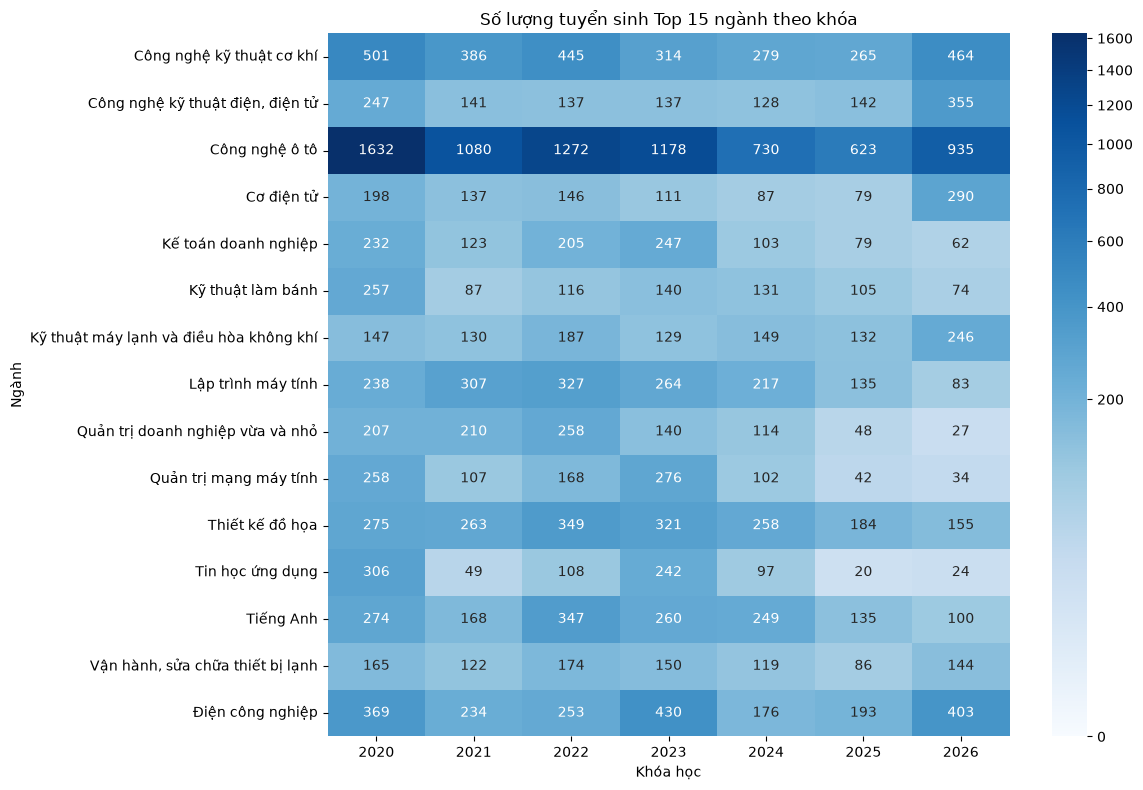

In [87]:
import matplotlib.colors as colors

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    norm=colors.PowerNorm(
        gamma=0.35,
        vmin=0,
        vmax=heatmap_data.to_numpy().max()
    )
)

plt.title("Số lượng tuyển sinh Top 15 ngành theo khóa")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

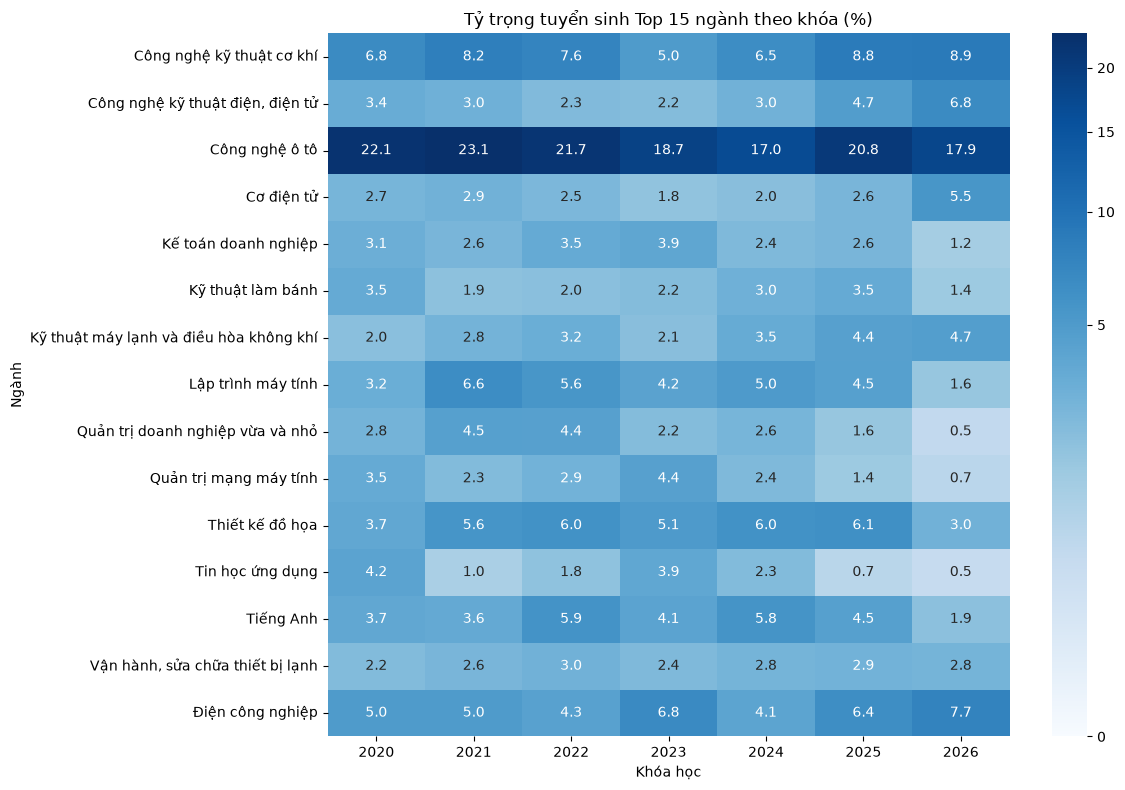

In [112]:
import matplotlib.colors as colors

# Tổng số sinh viên của từng năm
total_year = (
    df_clean
    .groupby("Khóa học")
    .size()
)

# Chuyển số lượng thành tỷ trọng %
heatmap_pct = (
    heatmap_data
    .div(total_year, axis=1)
    * 100
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    norm=colors.PowerNorm(
        gamma=0.35,
        vmin=0,
        vmax=heatmap_pct.to_numpy().max()
    )
)

plt.title("Tỷ trọng tuyển sinh Top 15 ngành theo khóa (%)")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

In [88]:
major_level_year = (
    df_clean
    .groupby([
        "Khóa học",
        "Bậc đào tạo",
        "Ngành"
    ])
    .size()
    .reset_index(name="Số lượng")
)

display(major_level_year.head(20))

,Khóa học,Bậc đào tạo,Ngành,Số lượng
0,2020,Cao đẳng,Bảo trì hệ thống thiết bị công nghiệp,25
1,2020,Cao đẳng,Chế tạo khuôn mẫu,20
2,2020,Cao đẳng,Công nghệ chế tạo máy,170
3,2020,Cao đẳng,Công nghệ kỹ thuật cơ khí,387
4,2020,Cao đẳng,Công nghệ kỹ thuật máy tính,75
5,2020,Cao đẳng,Công nghệ kỹ thuật nhiệt,154
6,2020,Cao đẳng,Công nghệ kỹ thuật điều khiển và tự động hóa,91
7,2020,Cao đẳng,"Công nghệ kỹ thuật điện, điện tử",193
8,2020,Cao đẳng,Công nghệ may,69
9,2020,Cao đẳng,Công nghệ ô tô,1244


In [89]:
major_levels = (
    df_clean
    .groupby("Ngành")["Bậc đào tạo"]
    .nunique()
    .sort_values(ascending=False)
)

display(major_levels)

Ngành
An ninh mạng                                    2
Công nghệ kỹ thuật cơ khí                       2
Công nghệ chế tạo máy                           2
Công nghệ kỹ thuật nhiệt                        2
Cơ điện tử                                      2
Công nghệ ô tô                                  2
Công nghệ may                                   2
Công nghệ kỹ thuật điện, điện tử                2
Công nghệ kỹ thuật điện tử, truyền thông        2
Lắp đặt thiết bị lạnh                           2
Lập trình máy tính                              2
Logistics                                       2
Kỹ thuật máy lạnh và điều hòa không khí         2
Kỹ thuật làm bánh                               2
Kỹ thuật Xây dựng                               2
Kế toán doanh nghiệp                            2
Cắt gọt kim loại                                2
Đồ họa đa phương tiện                           2
Điện tử công nghiệp                             2
Tin học ứng dụng                            

In [90]:
major_level_year = (
    df_clean
    .groupby(["Khóa học", "Bậc đào tạo", "Ngành"])
    .size()
    .reset_index(name="Số lượng")
)

display(major_level_year.head(20))

,Khóa học,Bậc đào tạo,Ngành,Số lượng
0,2020,Cao đẳng,Bảo trì hệ thống thiết bị công nghiệp,25
1,2020,Cao đẳng,Chế tạo khuôn mẫu,20
2,2020,Cao đẳng,Công nghệ chế tạo máy,170
3,2020,Cao đẳng,Công nghệ kỹ thuật cơ khí,387
4,2020,Cao đẳng,Công nghệ kỹ thuật máy tính,75
5,2020,Cao đẳng,Công nghệ kỹ thuật nhiệt,154
6,2020,Cao đẳng,Công nghệ kỹ thuật điều khiển và tự động hóa,91
7,2020,Cao đẳng,"Công nghệ kỹ thuật điện, điện tử",193
8,2020,Cao đẳng,Công nghệ may,69
9,2020,Cao đẳng,Công nghệ ô tô,1244


In [113]:
top10_cd = (
    df_clean[df_clean["Bậc đào tạo"] == "Cao đẳng"]
    .groupby("Ngành")
    .size()
    .nlargest(10)
    .index
)

cd_year = major_level_year[
    (major_level_year["Bậc đào tạo"] == "Cao đẳng") &
    (major_level_year["Ngành"].isin(top10_cd))
]

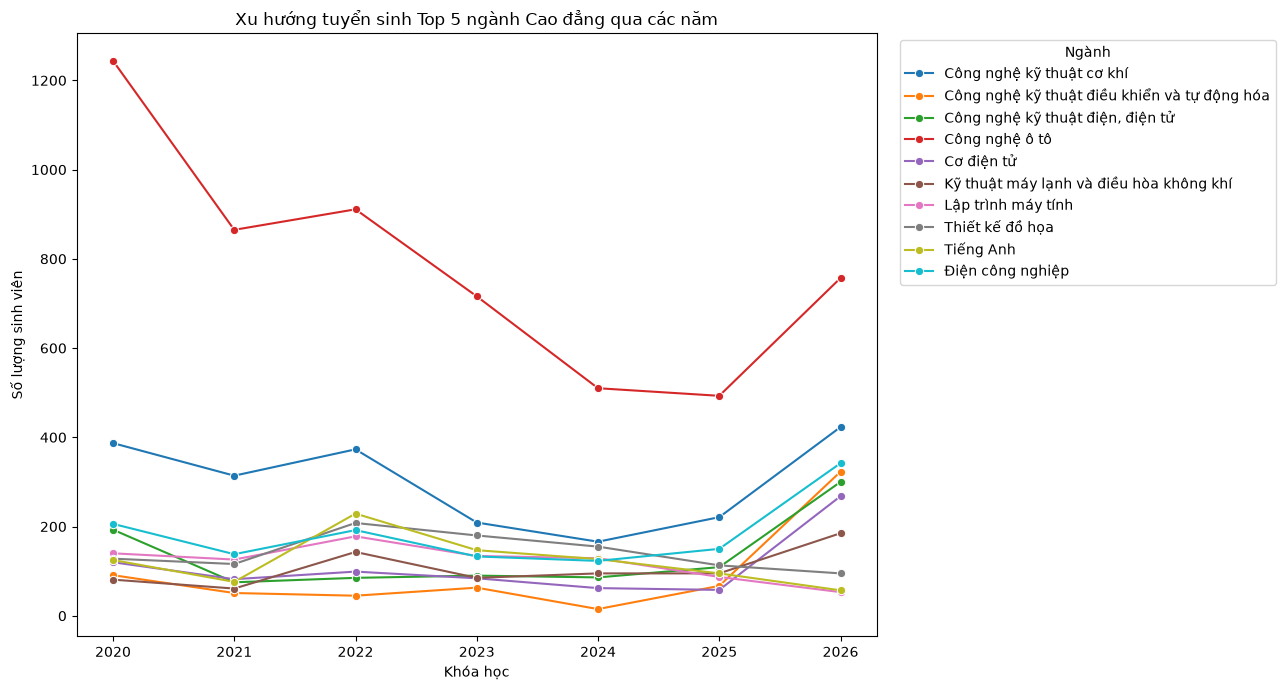

In [114]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=cd_year,
    x="Khóa học",
    y="Số lượng",
    hue="Ngành",
    marker="o"
)

plt.title("Xu hướng tuyển sinh Top 5 ngành Cao đẳng qua các năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.legend(
    title="Ngành",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [115]:
top10_tc = (
    df_clean[df_clean["Bậc đào tạo"] == "Trung cấp"]
    .groupby("Ngành")
    .size()
    .nlargest(10)
    .index
)

tc_year = major_level_year[
    (major_level_year["Bậc đào tạo"] == "Trung cấp") &
    (major_level_year["Ngành"].isin(top10_tc))
]

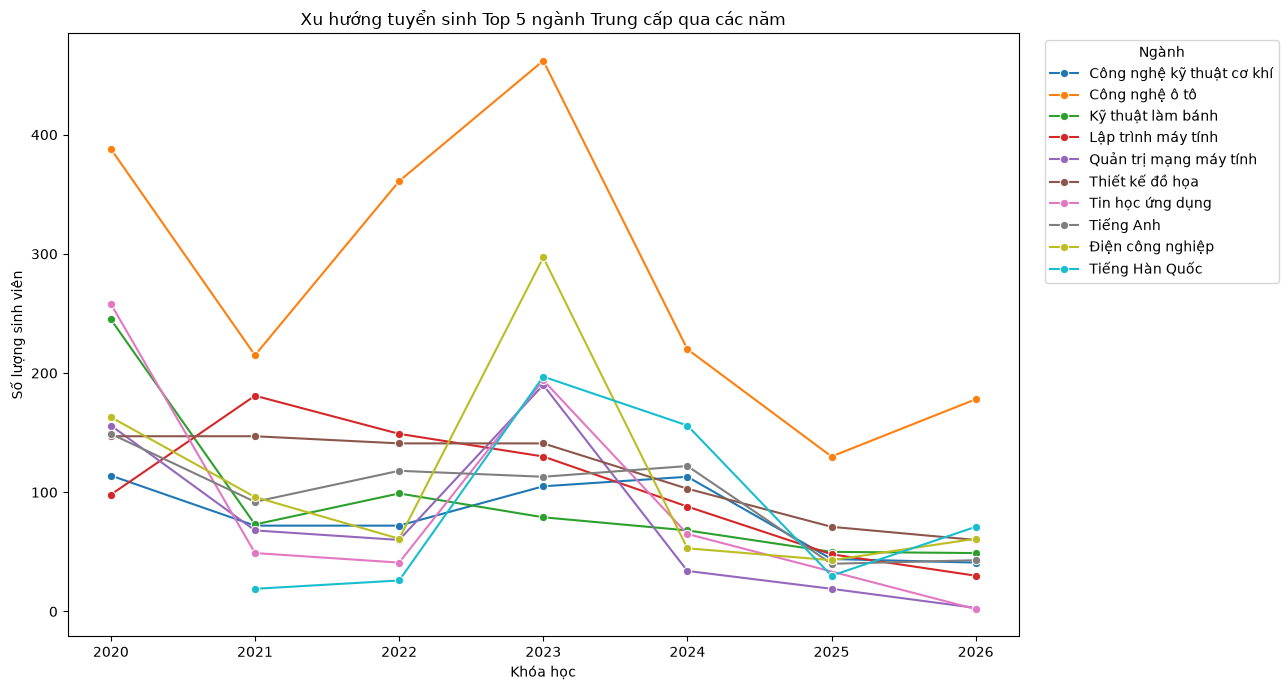

In [116]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=tc_year,
    x="Khóa học",
    y="Số lượng",
    hue="Ngành",
    marker="o"
)

plt.title("Xu hướng tuyển sinh Top 5 ngành Trung cấp qua các năm")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.legend(
    title="Ngành",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

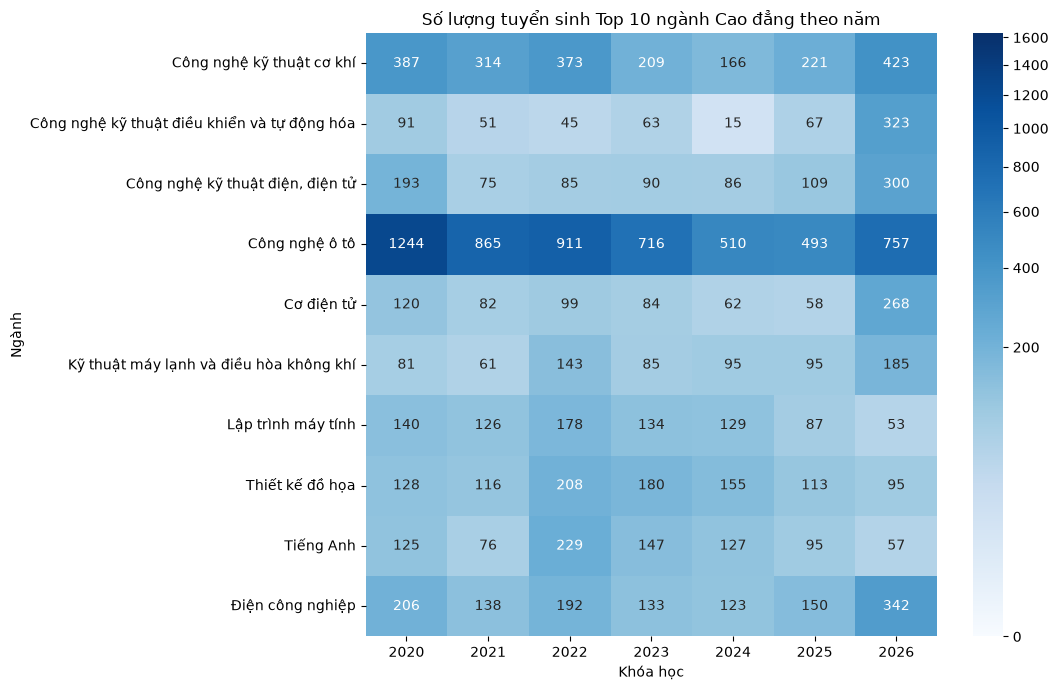

In [127]:
cd_heatmap = (
    cd_year
    .pivot(
        index="Ngành",
        columns="Khóa học",
        values="Số lượng"
    )
    .fillna(0)
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    cd_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    norm=colors.PowerNorm(
    gamma=0.35,
    vmin=0,
    vmax=heatmap_data.to_numpy().max()
    )
)

plt.title("Số lượng tuyển sinh Top 10 ngành Cao đẳng theo năm")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

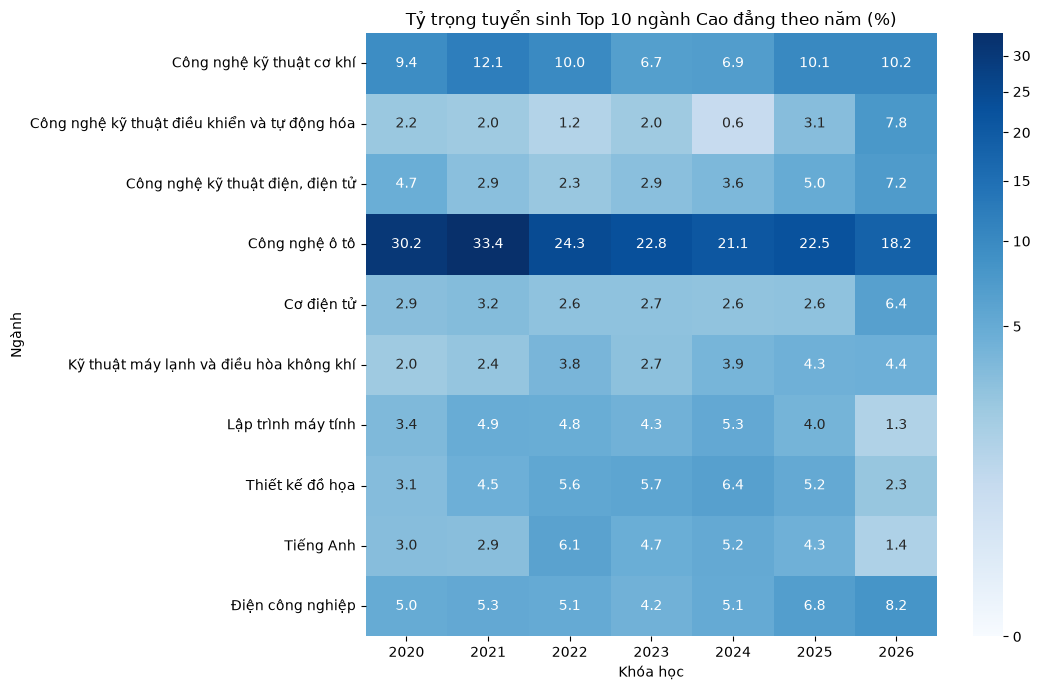

In [128]:
# Tổng số sinh viên Cao đẳng theo từng năm
total_cd_year = (
    df_clean[df_clean["Bậc đào tạo"] == "Cao đẳng"]
    .groupby("Khóa học")
    .size()
)

# Chuyển số lượng thành tỷ trọng %
cd_heatmap_pct = (
    cd_heatmap
    .div(total_cd_year, axis=1)
    * 100
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    cd_heatmap_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    norm=colors.PowerNorm(
        gamma=0.35,
        vmin=0,
        vmax=cd_heatmap_pct.to_numpy().max()
    )
)

plt.title("Tỷ trọng tuyển sinh Top 10 ngành Cao đẳng theo năm (%)")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

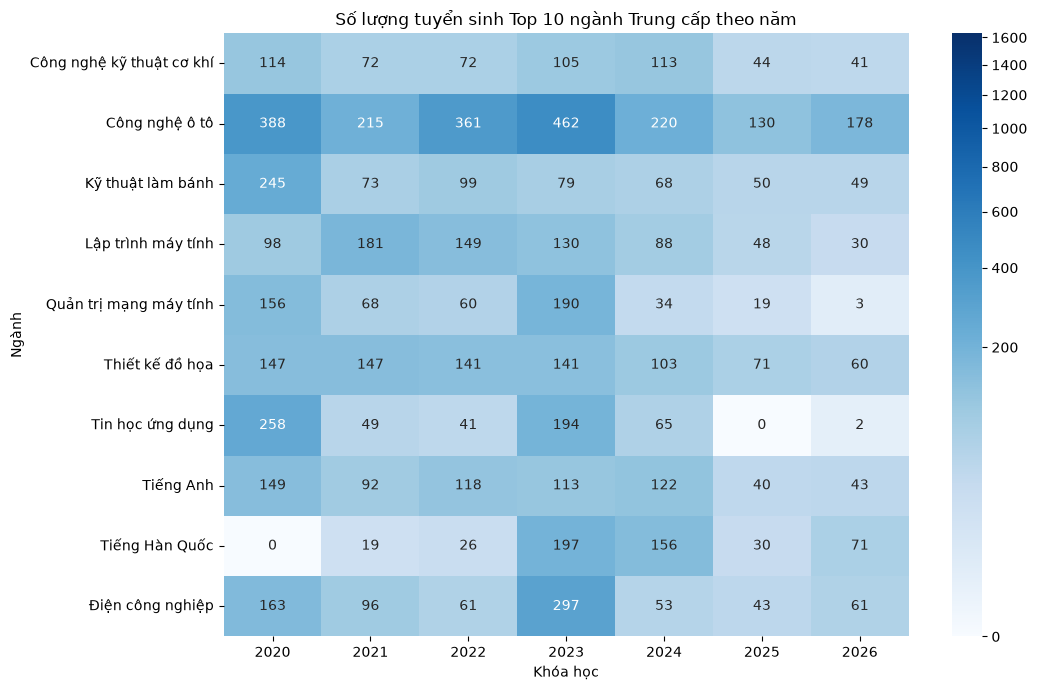

In [129]:
tc_heatmap = (
    tc_year
    .pivot(
        index="Ngành",
        columns="Khóa học",
        values="Số lượng"
    )
    .fillna(0)
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    tc_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    norm=colors.PowerNorm(
    gamma=0.35,
    vmin=0,
    vmax=heatmap_data.to_numpy().max()
    )
)

plt.title("Số lượng tuyển sinh Top 10 ngành Trung cấp theo năm")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

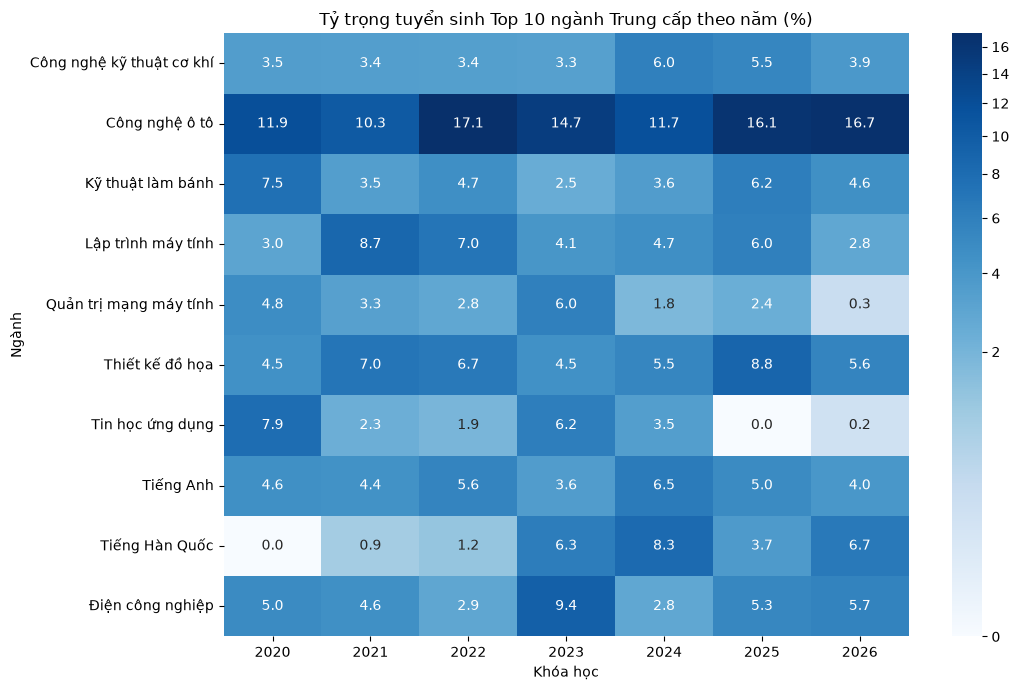

In [130]:
# Tổng số sinh viên Trung cấp theo từng năm
total_tc_year = (
    df_clean[df_clean["Bậc đào tạo"] == "Trung cấp"]
    .groupby("Khóa học")
    .size()
)

# Chuyển số lượng thành tỷ trọng %
tc_heatmap_pct = (
    tc_heatmap
    .div(total_tc_year, axis=1)
    * 100
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    tc_heatmap_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    norm=colors.PowerNorm(
        gamma=0.35,
        vmin=0,
        vmax=tc_heatmap_pct.to_numpy().max()
    )
)

plt.title("Tỷ trọng tuyển sinh Top 10 ngành Trung cấp theo năm (%)")
plt.xlabel("Khóa học")
plt.ylabel("Ngành")

plt.tight_layout()
plt.show()

In [97]:
#Ngành × Tên tỉnh THPT

In [98]:
major_province = (
    df_clean[
        df_clean["Tên tỉnh THPT"] != "Không xác định"
    ]
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .reset_index(name="Số lượng")
)

display(major_province.head())

,Ngành,Tên tỉnh THPT,Số lượng
0,An ninh mạng,An Giang,4
1,An ninh mạng,Bình Thuận,1
2,An ninh mạng,Bình Định,5
3,An ninh mạng,Bạc Liêu,2
4,An ninh mạng,Bắc Giang,1


In [99]:
top10_major = (
    df_clean
    .groupby("Ngành")
    .size()
    .nlargest(10)
    .index
)

top_major_province = major_province[
    major_province["Ngành"].isin(top10_major)
]

In [100]:
top5_province_each_major = (
    top_major_province
    .sort_values(
        ["Ngành", "Số lượng"],
        ascending=[True, False]
    )
    .groupby("Ngành")
    .head(5)
)

display(top5_province_each_major)

,Ngành,Tên tỉnh THPT,Số lượng
154,Công nghệ kỹ thuật cơ khí,Hồ Chí Minh,773
157,Công nghệ kỹ thuật cơ khí,Long An,164
180,Công nghệ kỹ thuật cơ khí,Tây Ninh,164
139,Công nghệ kỹ thuật cơ khí,Bến Tre,140
176,Công nghệ kỹ thuật cơ khí,Tiền Giang,108
470,"Công nghệ kỹ thuật điện, điện tử",Hồ Chí Minh,351
486,"Công nghệ kỹ thuật điện, điện tử",Quảng Ngãi,59
450,"Công nghệ kỹ thuật điện, điện tử",Bình Thuận,52
476,"Công nghệ kỹ thuật điện, điện tử",Lâm Đồng,47
474,"Công nghệ kỹ thuật điện, điện tử",Long An,46


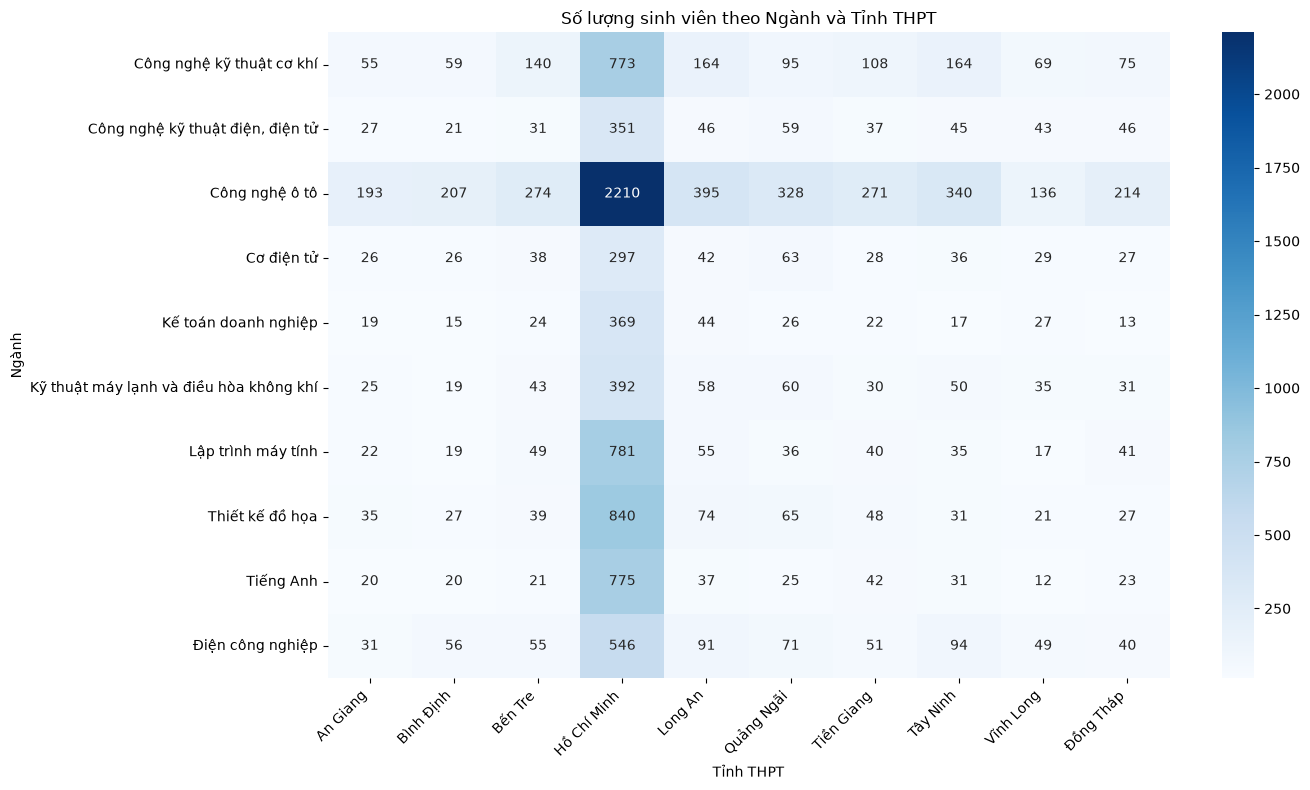

In [101]:
# Top 10 ngành
top10_major = (
    df_clean
    .groupby("Ngành")
    .size()
    .nlargest(10)
    .index
)

# Top 10 tỉnh THPT
top10_province = (
    df_clean[
        df_clean["Tên tỉnh THPT"] != "Không xác định"
    ]
    .groupby("Tên tỉnh THPT")
    .size()
    .nlargest(10)
    .index
)

# Tạo bảng
major_province_heatmap = (
    df_clean[
        df_clean["Ngành"].isin(top10_major)
        & df_clean["Tên tỉnh THPT"].isin(top10_province)
    ]
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    major_province_heatmap,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Số lượng sinh viên theo Ngành và Tỉnh THPT")
plt.xlabel("Tỉnh THPT")
plt.ylabel("Ngành")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

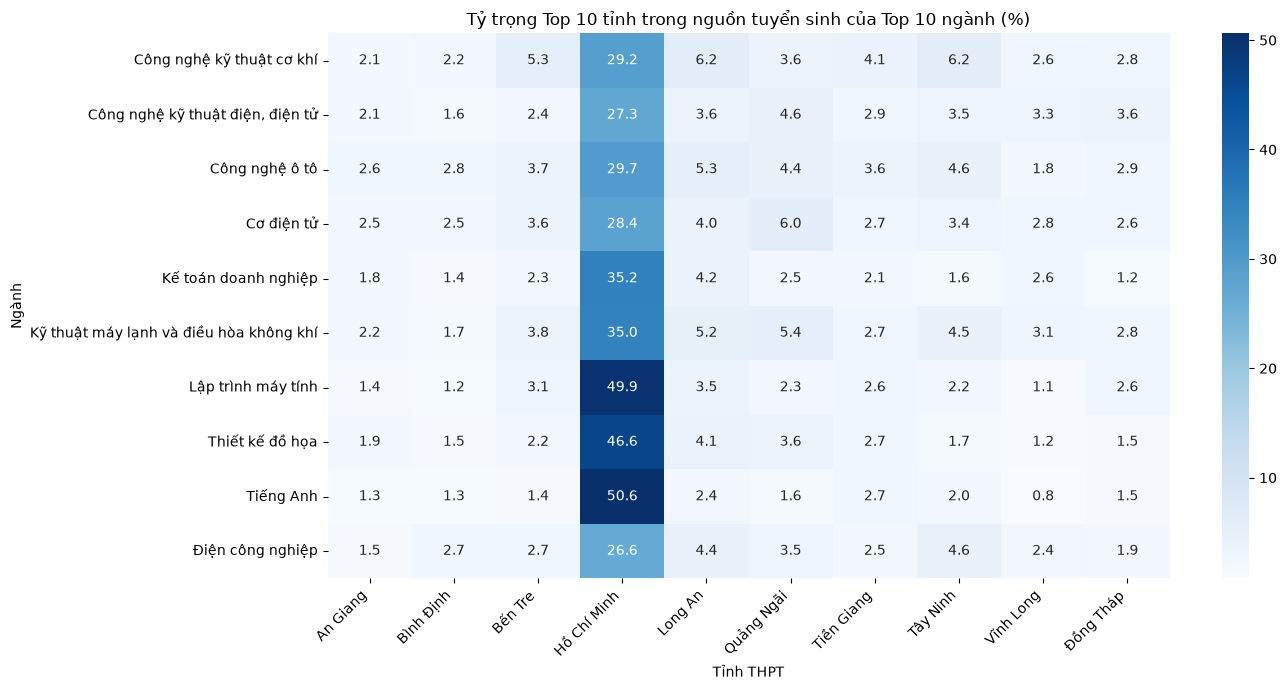

In [102]:
# Tổng SV của Top 10 ngành từ TẤT CẢ tỉnh
major_total = (
    df_clean[
        (df_clean["Ngành"].isin(top10_major))
        & (df_clean["Tên tỉnh THPT"] != "Không xác định")
    ]
    .groupby("Ngành")
    .size()
)

major_province_pct = (
    major_province_heatmap
    .div(major_total, axis=0)
    * 100
)
plt.figure(figsize=(14, 7))

sns.heatmap(
    major_province_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Tỷ trọng Top 10 tỉnh trong nguồn tuyển sinh của Top 10 ngành (%)")
plt.xlabel("Tỉnh THPT")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

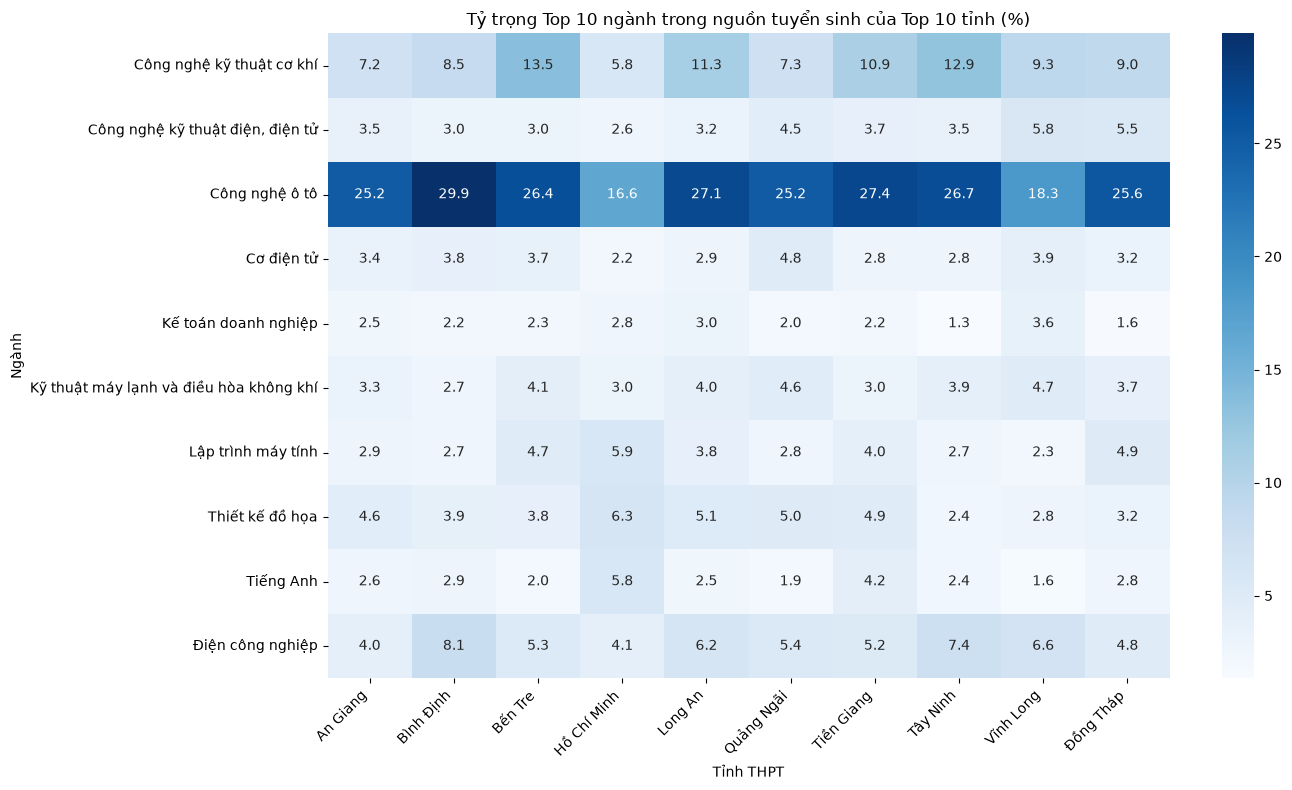

In [103]:
# Top 10 ngành
top10_major = (
    df_clean
    .groupby("Ngành")
    .size()
    .nlargest(10)
    .index
)

# Top 10 tỉnh
top10_province = (
    df_clean[
        df_clean["Tên tỉnh THPT"] != "Không xác định"
    ]
    .groupby("Tên tỉnh THPT")
    .size()
    .nlargest(10)
    .index
)

# Bảng count: chỉ Top 10 ngành × Top 10 tỉnh
major_province_heatmap = (
    df_clean[
        df_clean["Ngành"].isin(top10_major)
        & df_clean["Tên tỉnh THPT"].isin(top10_province)
    ]
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .unstack(fill_value=0)
)

province_total = (
    df_clean[
        df_clean["Tên tỉnh THPT"].isin(top10_province)
    ]
    .groupby("Tên tỉnh THPT")
    .size()
)

province_major_pct = (
    major_province_heatmap
    .div(province_total, axis=1)
    * 100
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    province_major_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Tỷ trọng Top 10 ngành trong nguồn tuyển sinh của Top 10 tỉnh (%)")
plt.xlabel("Tỉnh THPT")
plt.ylabel("Ngành")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

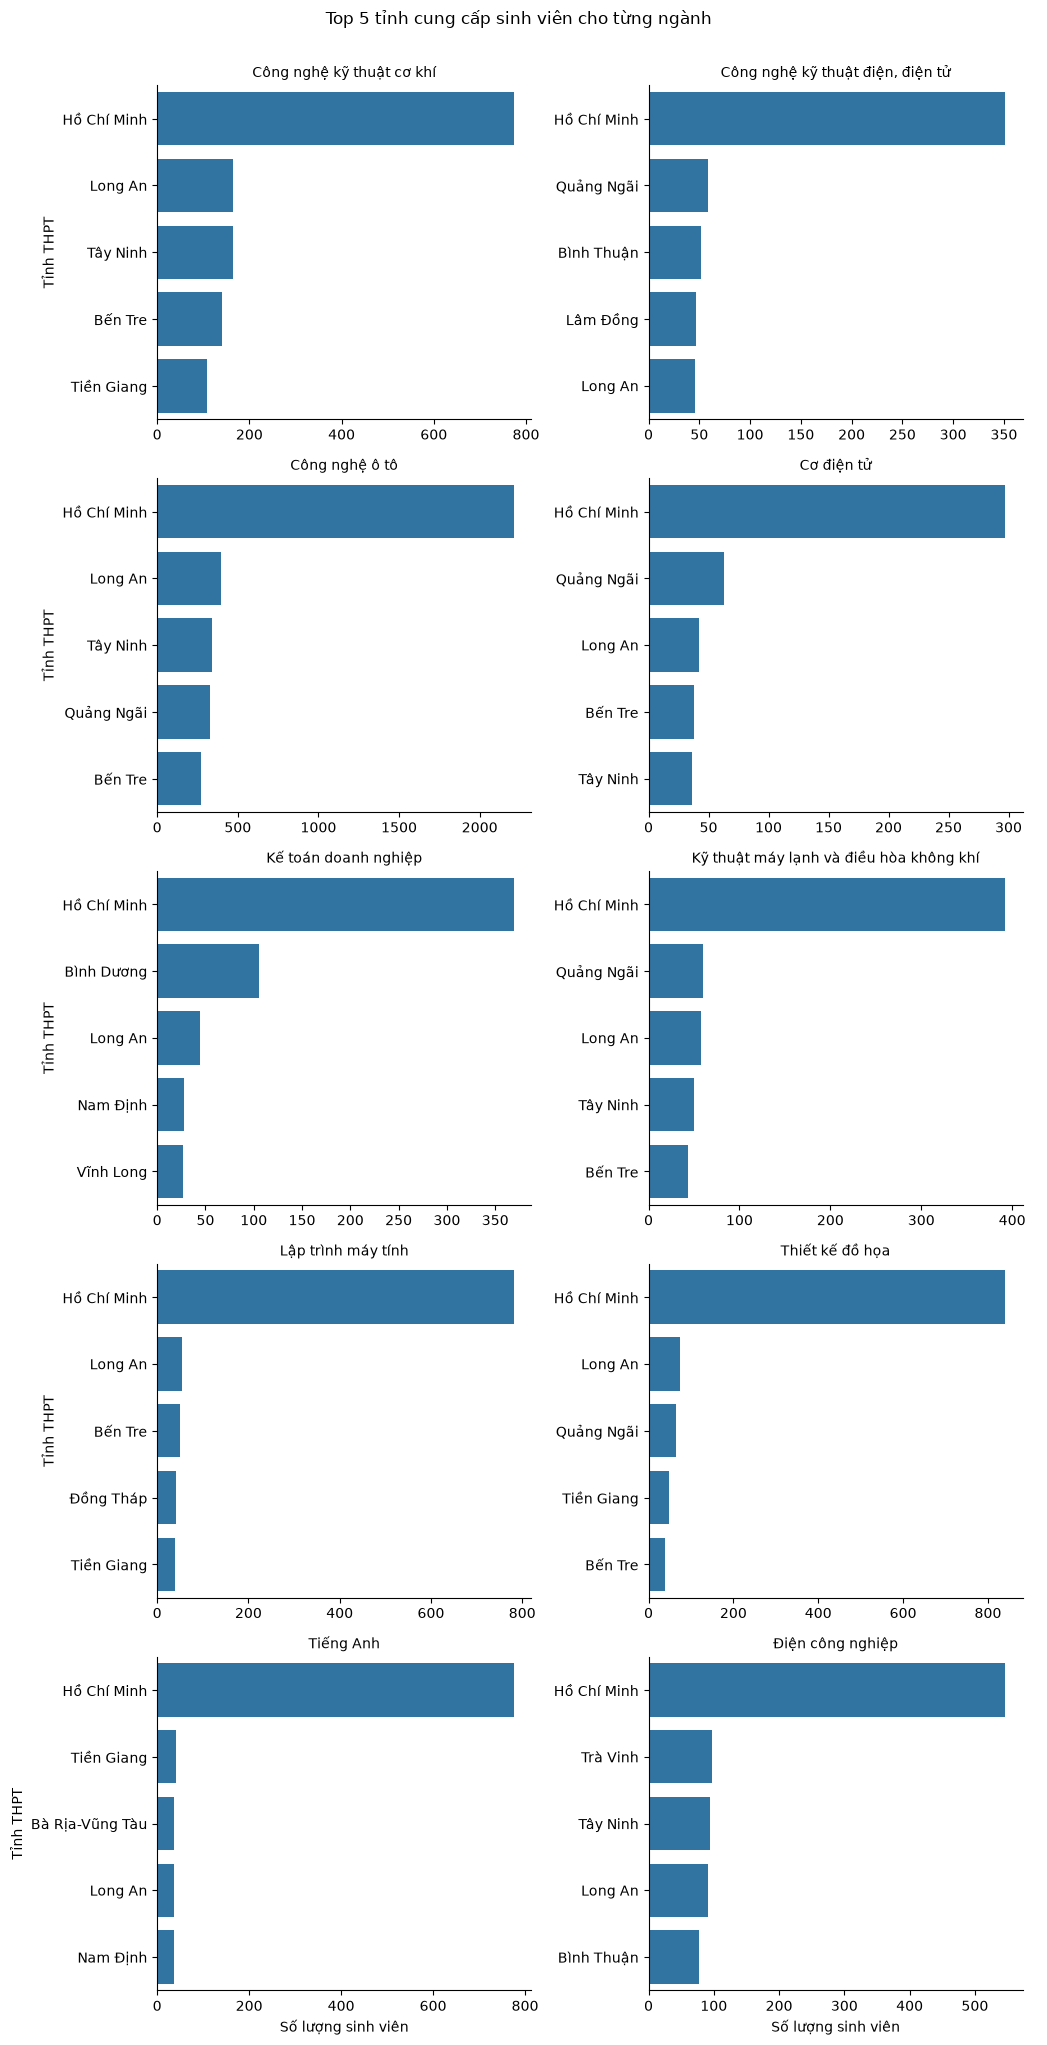

In [104]:
data = (
    df_clean[
        df_clean["Ngành"].isin(top10_major)
        & (df_clean["Tên tỉnh THPT"] != "Không xác định")
    ]
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .reset_index(name="Số lượng")
)

# Top 5 tỉnh của mỗi ngành
top5 = (
    data
    .sort_values(
        ["Ngành", "Số lượng"],
        ascending=[True, False]
    )
    .groupby("Ngành")
    .head(5)
)

g = sns.catplot(
    data=top5,
    x="Số lượng",
    y="Tên tỉnh THPT",
    col="Ngành",
    col_wrap=2,
    kind="bar",
    sharex=False,
    sharey=False,
    height=4,
    aspect=1.3
)

g.set_titles("{col_name}")
g.set_axis_labels("Số lượng sinh viên", "Tỉnh THPT")

g.fig.suptitle(
    "Top 5 tỉnh cung cấp sinh viên cho từng ngành",
    y=1.02
)

plt.show()

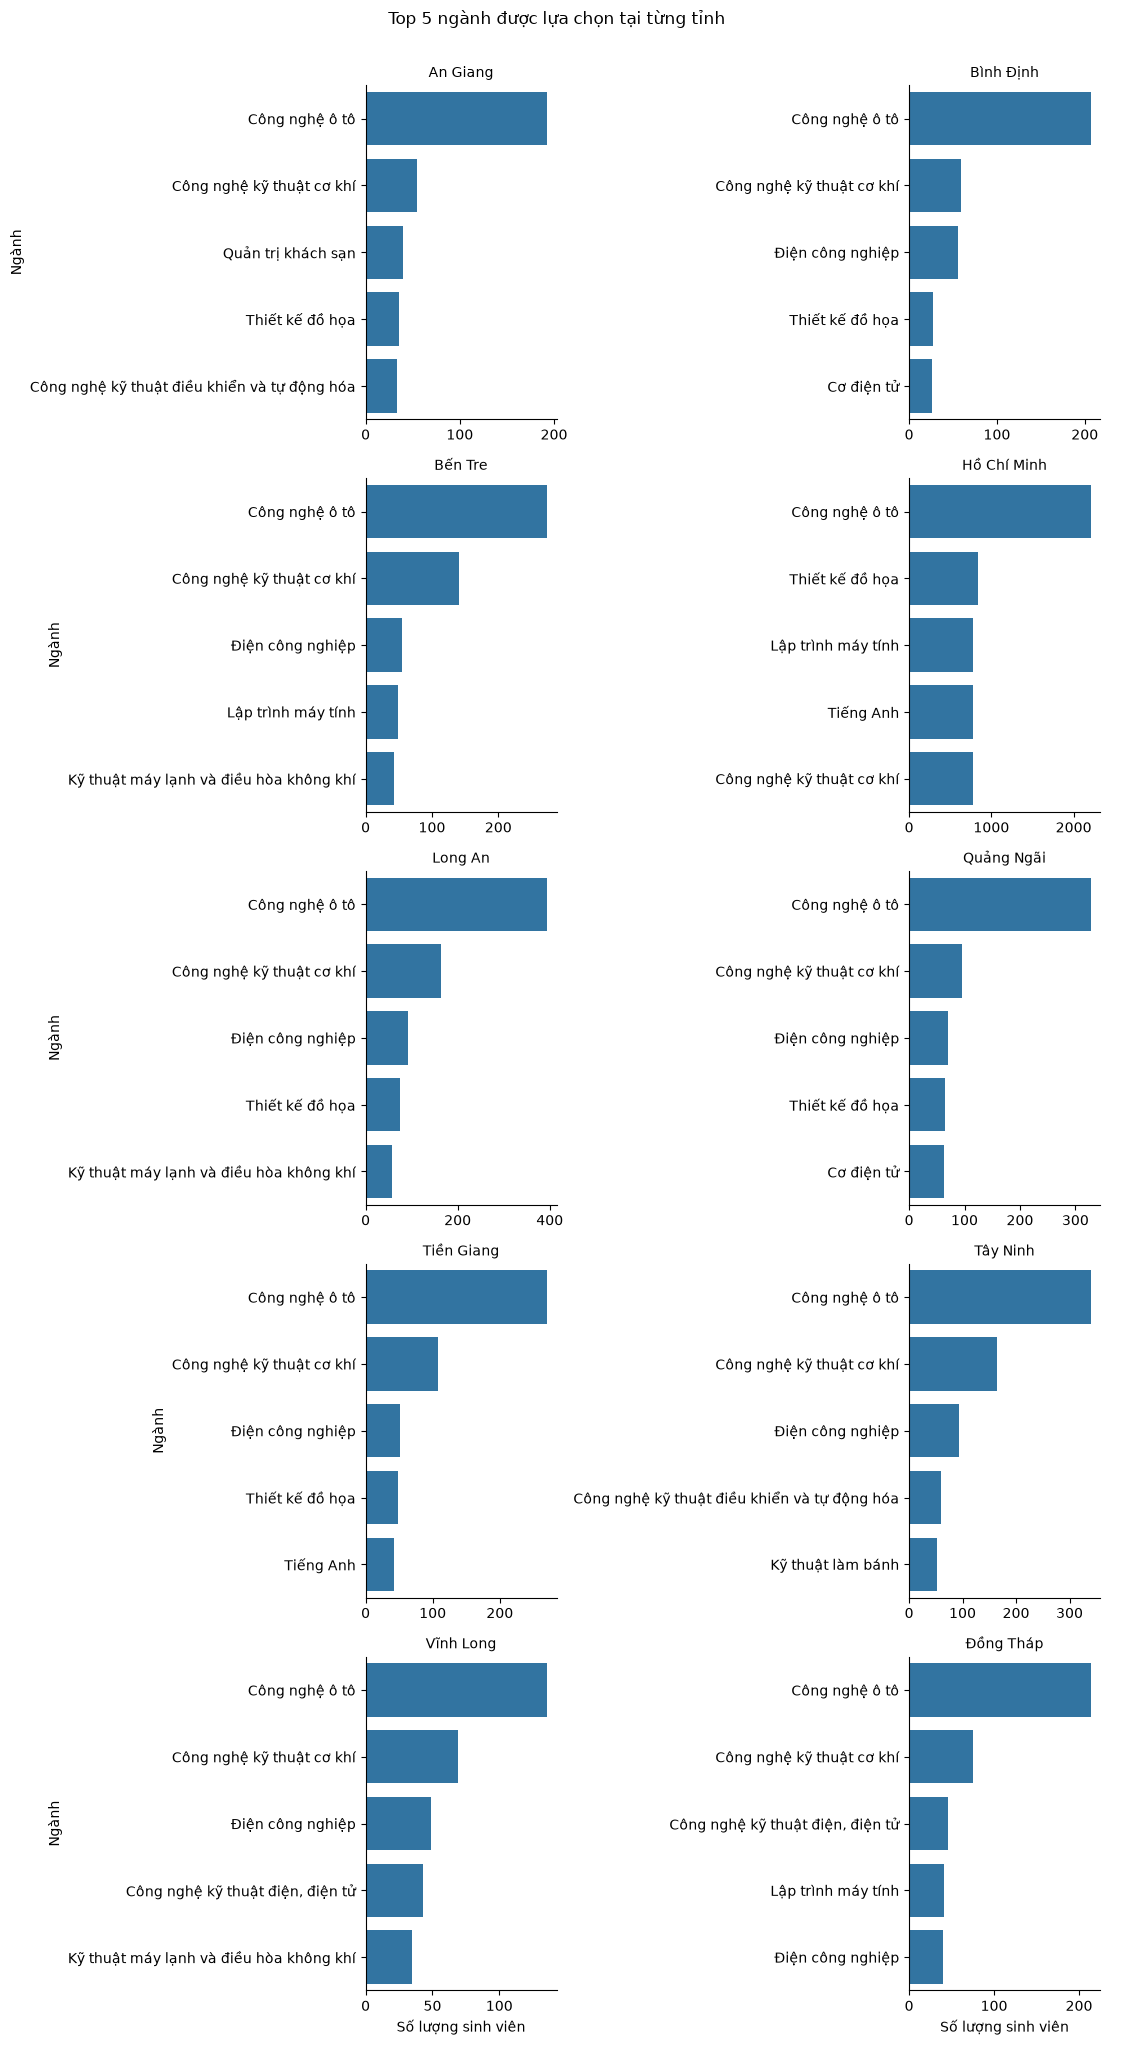

In [105]:
data2 = (
    df_clean[
        df_clean["Tên tỉnh THPT"].isin(top10_province)
    ]
    .groupby(["Tên tỉnh THPT", "Ngành"])
    .size()
    .reset_index(name="Số lượng")
)

top5_major_province = (
    data2
    .sort_values(
        ["Tên tỉnh THPT", "Số lượng"],
        ascending=[True, False]
    )
    .groupby("Tên tỉnh THPT")
    .head(5)
)

g = sns.catplot(
    data=top5_major_province,
    x="Số lượng",
    y="Ngành",
    col="Tên tỉnh THPT",
    col_wrap=2,
    kind="bar",
    sharex=False,
    sharey=False,
    height=4,
    aspect=1.4
)

g.set_titles("{col_name}")
g.set_axis_labels("Số lượng sinh viên", "Ngành")

g.fig.suptitle(
    "Top 5 ngành được lựa chọn tại từng tỉnh",
    y=1.02
)

plt.show()

In [107]:
# Loại tỉnh "Không xác định"
temp = df_clean[
    df_clean["Tên tỉnh THPT"] != "Không xác định"
].copy()

# Số sinh viên theo Ngành × Tỉnh
major_province_all = (
    temp
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .unstack(fill_value=0)
)

# % tỉnh trong từng ngành
major_province_all_pct = (
    major_province_all
    .div(major_province_all.sum(axis=1), axis=0)
    * 100
)

print("Trong mỗi ngành, sinh viên thuộc các tỉnh nào?")

for major in major_province_all_pct.index:

    # Tổng số sinh viên của ngành
    total = major_province_all.loc[major].sum()

    # Chỉ xét ngành có ít nhất 30 sinh viên
    if total < 30:
        continue

    # Các tỉnh chiếm > 10%
    result = (
        major_province_all_pct.loc[major]
        [major_province_all_pct.loc[major] > 10]
        .sort_values(ascending=False)
    )

    if len(result) > 0:
        print(f"\n{major} - Tổng: {total} SV")

        for province, pct in result.items():
            n = major_province_all.loc[major, province]

            print(
                f"  {province}: {pct:.1f}% ({n}/{total} SV)"
            )

Trong mỗi ngành, sinh viên thuộc các tỉnh nào?

An ninh mạng - Tổng: 232 SV
  Hồ Chí Minh: 46.6% (108/232 SV)

Bảo trì hệ thống thiết bị công nghiệp - Tổng: 53 SV
  Tây Ninh: 22.6% (12/53 SV)
  Hồ Chí Minh: 15.1% (8/53 SV)

Công nghệ chế tạo máy - Tổng: 707 SV
  Hồ Chí Minh: 33.5% (237/707 SV)

Công nghệ kỹ thuật cơ khí - Tổng: 2649 SV
  Hồ Chí Minh: 29.2% (773/2649 SV)

Công nghệ kỹ thuật máy tính - Tổng: 551 SV
  Hồ Chí Minh: 47.9% (264/551 SV)

Công nghệ kỹ thuật nhiệt - Tổng: 407 SV
  Hồ Chí Minh: 22.1% (90/407 SV)

Công nghệ kỹ thuật phần cứng máy tính - Tổng: 331 SV
  Hồ Chí Minh: 49.8% (165/331 SV)

Công nghệ kỹ thuật điều khiển tự động - Tổng: 128 SV
  Hồ Chí Minh: 46.9% (60/128 SV)

Công nghệ kỹ thuật điều khiển và tự động hóa - Tổng: 654 SV
  Hồ Chí Minh: 17.4% (114/654 SV)

Công nghệ kỹ thuật điện tử, truyền thông - Tổng: 31 SV
  Hồ Chí Minh: 32.3% (10/31 SV)

Công nghệ kỹ thuật điện, điện tử - Tổng: 1284 SV
  Hồ Chí Minh: 27.3% (351/1284 SV)

Công nghệ may - Tổng: 292 SV
  

In [108]:
# Loại "Không xác định"
temp = df_clean[
    df_clean["Tên tỉnh THPT"] != "Không xác định"
].copy()

# Số sinh viên theo Ngành × Tỉnh
province_major_all = (
    temp
    .groupby(["Ngành", "Tên tỉnh THPT"])
    .size()
    .unstack(fill_value=0)
)

# % ngành trong từng tỉnh
province_major_all_pct = (
    province_major_all
    .div(province_major_all.sum(axis=0), axis=1)
    * 100
)

print("Trong mỗi tỉnh, sinh viên thích học các ngành nào?")

# In các ngành > 10%, chỉ xét tỉnh có trên 30 SV
for province in province_major_all_pct.columns:

    # Tổng số sinh viên của tỉnh
    total = province_major_all[province].sum()

    # Bỏ tỉnh có <= 30 sinh viên
    if total <= 30:
        continue

    # Các ngành chiếm > 10%
    result = (
        province_major_all_pct[province]
        [province_major_all_pct[province] > 10]
        .sort_values(ascending=False)
    )

    if len(result) > 0:
        print(f"\n{province} - Tổng: {total} SV")

        for major, pct in result.items():
            n = province_major_all.loc[major, province]

            print(
                f"  {major}: {pct:.1f}% ({n}/{total} SV)"
            )

Trong mỗi tỉnh, sinh viên thích học các ngành nào?

An Giang - Tổng: 767 SV
  Công nghệ ô tô: 25.2% (193/767 SV)

Bà Rịa-Vũng Tàu - Tổng: 451 SV
  Tiếng Hàn Quốc: 15.5% (70/451 SV)
  Điện công nghiệp: 11.8% (53/451 SV)

Bình Dương - Tổng: 692 SV
  Tin học ứng dụng: 25.7% (178/692 SV)
  Kế toán doanh nghiệp: 15.2% (105/692 SV)
  Quản trị mạng máy tính: 12.1% (84/692 SV)

Bình Phước - Tổng: 603 SV
  Tiếng Hàn Quốc: 19.2% (116/603 SV)
  Công nghệ ô tô: 18.6% (112/603 SV)

Bình Thuận - Tổng: 643 SV
  Công nghệ ô tô: 28.3% (182/643 SV)
  Điện công nghiệp: 12.0% (77/643 SV)

Bình Định - Tổng: 693 SV
  Công nghệ ô tô: 29.9% (207/693 SV)

Bạc Liêu - Tổng: 216 SV
  Công nghệ ô tô: 27.8% (60/216 SV)
  Công nghệ kỹ thuật cơ khí: 11.1% (24/216 SV)

Bắc Giang - Tổng: 123 SV
  Công nghệ ô tô: 17.9% (22/123 SV)

Bắc Ninh - Tổng: 206 SV
  Công nghệ ô tô: 14.1% (29/206 SV)

Bến Tre - Tổng: 1037 SV
  Công nghệ ô tô: 26.4% (274/1037 SV)
  Công nghệ kỹ thuật cơ khí: 13.5% (140/1037 SV)

Campuchia - Tổng: 

In [109]:
#Phân tích sâu trường và TP.HCM

In [110]:
temp = df_clean.copy()

valid = (
    temp["Trường tốt nghiệp"].notna()
    & temp["Trường tốt nghiệp"].ne("KHÔNG Xác Định")
)

summary = (
    temp.assign(Có_dữ_liệu=valid)
    .groupby("Bậc đào tạo")
    .agg(
        Tổng=("Trường tốt nghiệp", "size"),
        Có_dữ_liệu=("Có_dữ_liệu", "sum")
    )
)

summary["Missing"] = summary["Tổng"] - summary["Có_dữ_liệu"]

summary["% Có dữ liệu"] = (
    summary["Có_dữ_liệu"] / summary["Tổng"] * 100
).round(1)

summary["% Missing"] = (
    summary["Missing"] / summary["Tổng"] * 100
).round(1)

print(summary)

              Tổng  Có_dữ_liệu  Missing  % Có dữ liệu  % Missing
Bậc đào tạo                                                     
Cao đẳng     22364       20603     1761          92.1        7.9
Trung cấp    14358        4774     9584          33.2       66.8
